# Question 7

In [29]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import VarianceThreshold
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

In [ ]:
X_train = pd.read_csv('./data/TinyMNIST/trainData.csv', header=None)
y_train = pd.read_csv('./data/TinyMNIST/trainLabels.csv', header=None).values.ravel()
X_test = pd.read_csv('./data/TinyMNIST/testData.csv', header=None)
y_test = pd.read_csv('./data/TinyMNIST/testLabels.csv', header=None).values.ravel()
class_names = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

tr_samples_size, _ = X_train.shape
all_data = np.vstack((X_train,X_test))
sel = VarianceThreshold(threshold=0.90*(1-0.90))
all_data = sel.fit_transform(all_data)
train_data = all_data[:tr_samples_size]
test_data = all_data[tr_samples_size:]

tr_samples_size, feature_size = train_data.shape
te_samples_size, _ = test_data.shape
print('Train Data Samples:',tr_samples_size,
      ', Test Data Samples',te_samples_size,
      ', Feature Size(after feature-selection):', feature_size)

X_train = pd.DataFrame(train_data ,columns=sel.get_feature_names_out())
X_test = pd.DataFrame(test_data ,columns=sel.get_feature_names_out())

Train Data Samples: 5000 , Test Data Samples 2500 , Feature Size(after feature-selection): 62


In [8]:
X_train.columns

Index(['x34', 'x35', 'x36', 'x47', 'x48', 'x49', 'x50', 'x51', 'x52', 'x60',
       'x61', 'x62', 'x63', 'x64', 'x65', 'x66', 'x74', 'x75', 'x76', 'x77',
       'x78', 'x79', 'x80', 'x88', 'x89', 'x90', 'x91', 'x92', 'x93', 'x94',
       'x102', 'x103', 'x104', 'x105', 'x106', 'x107', 'x108', 'x116', 'x117',
       'x118', 'x119', 'x120', 'x121', 'x122', 'x130', 'x131', 'x132', 'x133',
       'x134', 'x135', 'x136', 'x144', 'x145', 'x146', 'x147', 'x148', 'x149',
       'x158', 'x159', 'x160', 'x161', 'x162'],
      dtype='object')

In [32]:
def get_ccr(features):
    if not features:
        return 0
    model = GaussianNB()
    model.fit(X_train[features], y_train)
    preds = model.predict(X_test[features])
    return accuracy_score(y_test, preds) * 100

In [4]:
#Forward Selection
selected_features_fwd = []
remaining_features = list(X_train.columns)
best_ccr_fwd = 0

for i in range(len(X_train.columns)):
    scores = []
    for f in remaining_features:
        current_subset = selected_features_fwd + [f]
        scores.append((get_ccr(current_subset), f))
    
    scores.sort(reverse=True)
    current_best_ccr, best_f = scores[0]
    
    if current_best_ccr >= best_ccr_fwd:
        best_ccr_fwd = current_best_ccr
        selected_features_fwd.append(best_f)
        remaining_features.remove(best_f)
        print(f"Step {i+1}: Added {best_f:20} | CCR: {current_best_ccr:.2f}%")
    else:
        break

Step 1: Added x35                  | CCR: 22.12%
Step 2: Added x102                 | CCR: 30.88%
Step 3: Added x91                  | CCR: 38.32%
Step 4: Added x106                 | CCR: 45.08%
Step 5: Added x131                 | CCR: 49.48%
Step 6: Added x89                  | CCR: 53.48%
Step 7: Added x79                  | CCR: 57.36%
Step 8: Added x63                  | CCR: 60.32%
Step 9: Added x49                  | CCR: 62.92%
Step 10: Added x119                 | CCR: 65.56%
Step 11: Added x77                  | CCR: 67.24%
Step 12: Added x74                  | CCR: 68.80%
Step 13: Added x135                 | CCR: 70.40%
Step 14: Added x162                 | CCR: 71.52%
Step 15: Added x78                  | CCR: 72.64%
Step 16: Added x76                  | CCR: 73.60%
Step 17: Added x132                 | CCR: 74.40%
Step 18: Added x47                  | CCR: 74.96%
Step 19: Added x66                  | CCR: 75.40%
Step 20: Added x104                 | CCR: 75.88%
Step 21: 

In [34]:
#Backward Elimintation
selected_features_bwd = list(X_train.columns)
best_ccr_bwd = get_ccr(selected_features_bwd)
print(f"Initial (Full Set) CCR: {best_ccr_bwd:.2f}%")

step = 1
while len(selected_features_bwd) > 1:
    scores = []
    for f in selected_features_bwd:
        current_subset = [feat for feat in selected_features_bwd if feat != f]
        scores.append((get_ccr(current_subset), f))
    
    scores.sort(reverse=True)
    current_best_ccr, worst_f = scores[0]
    
    if current_best_ccr >= best_ccr_bwd:
        best_ccr_bwd = current_best_ccr
        selected_features_bwd.remove(worst_f)
        print(f"Step {step}: Removed {worst_f:20} | CCR: {current_best_ccr:.2f}%")
        step += 1
    else:
        break

Initial (Full Set) CCR: 76.48%
Step 1: Removed x36                  | CCR: 77.28%
Step 2: Removed x122                 | CCR: 77.76%
Step 3: Removed x108                 | CCR: 78.00%
Step 4: Removed x161                 | CCR: 78.48%
Step 5: Removed x93                  | CCR: 78.72%
Step 6: Removed x50                  | CCR: 78.92%
Step 7: Removed x107                 | CCR: 79.20%
Step 8: Removed x51                  | CCR: 79.48%
Step 9: Removed x134                 | CCR: 79.52%
Step 10: Removed x133                 | CCR: 79.52%


In [6]:
print(f"Forward Selection Best CCR: {best_ccr_fwd:.2f}% with {len(selected_features_fwd)} features")
print(f"Backward Elimination Best CCR: {best_ccr_bwd:.2f}% with {len(selected_features_bwd)} features")

Forward Selection Best CCR: 79.04% with 28 features
Backward Elimination Best CCR: 79.52% with 52 features


# Question 8

## Imports

In [1]:
import torch
import torch.nn as nn
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split, Subset
import torch.optim as optim

import torchsummary

import torchvision.models as models
from torchvision.transforms import v2
from PIL import Image

from torchmetrics import Accuracy
from tqdm import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report

## Utils & Functions

In [2]:
# Parameters
seed = 0

batch_size = 128

device = device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
def set_seed(seed):
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
      torch.cuda.manual_seed(seed)

In [4]:
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

In [ ]:
def train_one_epoch(model, train_loader, loss_fn, optimizer, epoch=None):
    model.train()
    loss_train = AverageMeter()
    acc_train = Accuracy(task="multiclass", num_classes=5).to(device)
    with tqdm(train_loader, unit="batch") as tepoch:
        for inputs, targets in tepoch:
            if epoch is not None:
                tepoch.set_description(f"Epoch {epoch}")
            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()
            
            outputs = model(inputs)
      
            loss = loss_fn(outputs, targets)

            loss.backward()
            optimizer.step()

            loss_train.update(loss.item())
            acc_train(outputs, targets.int())
            tepoch.set_postfix(loss=loss_train.avg, accuracy=100.*acc_train.compute().item())
    return model, loss_train.avg, acc_train.compute().item()

In [6]:
def validation(model, test_loader, loss_fn):
    model.eval()
    with torch.no_grad():
        loss_valid = AverageMeter()
        acc_valid = Accuracy(task="multiclass", num_classes=5).to(device)
        for i, (inputs, targets) in enumerate(test_loader):
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = loss_fn(outputs, targets)
      
            loss_valid.update(loss.item())
            acc_valid(outputs, targets.int())
    return loss_valid.avg, acc_valid.compute().item()

## Dataset & Transforms

In [7]:
transform = v2.Compose([
    v2.Resize((224, 224)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

In [ ]:
set_seed(seed)
train_set = ImageFolder('./data/flowers/train', transform=transform)
valid_set = ImageFolder('./data/flowers/val', transform=transform)

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=False)

## Define Models

In [9]:
class LinearModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(3*224*224, 5)
        
    def forward(self, x):
        return self.fc(self.flatten(x))

class ReLUModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(3*224*224, 128),
            nn.ReLU(),
            nn.Linear(128, 5)
        )
        
    def forward(self, x):
        return self.layers(self.flatten(x))
    
class ImprovedNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.network = nn.Sequential(
            nn.Linear(3*224*224, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 5)
        )
        
    def forward(self, x):
        return self.network(self.flatten(x))
    
class AlexNet5(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.model = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)

        for param in self.model.parameters():
            param.requires_grad = False

        in_features = self.model.classifier[6].in_features
        self.model.classifier[6] = nn.Linear(in_features, num_classes)

        for param in self.model.classifier[6].parameters():
            param.requires_grad = True

    def forward(self, x):
        return self.model(x)
    

class VGG16_5(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

        for param in self.model.parameters():
            param.requires_grad = False

        in_features = self.model.classifier[6].in_features
        self.model.classifier[6] = nn.Linear(in_features, num_classes)

        for param in self.model.classifier[6].parameters():
            param.requires_grad = True

    def forward(self, x):
        return self.model(x)

## Linear Model

### Initial Loss

In [18]:
set_seed(seed)
model1 = LinearModel().to(device)
loss_fn = nn.CrossEntropyLoss()

inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)
targets = targets.to(device)

with torch.no_grad():
  outputs = model1(inputs)
  loss = loss_fn(outputs, targets)

print(loss)

tensor(1.6065, device='cuda:0')


### Best Learning Rate

In [19]:
set_seed(seed)
loss_fn = nn.CrossEntropyLoss()

num_epochs = 3

for lr in [0.3, 0.1, 0.01, 0.001, 0.0001]:
  print(f'LR={lr}')

  model1 = LinearModel().to(device)
  optimizer = torch.optim.Adam(model1.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model1, _, _ = train_one_epoch(model1, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.3


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.52batch/s, accuracy=0, loss=2.15e+4]



LR=0.1


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.52batch/s, accuracy=12.1, loss=7.29e+3]



LR=0.01


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.52batch/s, accuracy=1.19, loss=770] 



LR=0.001


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.50batch/s, accuracy=8.7, loss=52.2] 



LR=0.0001


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.41batch/s, accuracy=0.593, loss=7.03]

### Train

In [20]:
loss_train_hist = []
loss_valid_hist = []

acc_train_hist = []
acc_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

In [22]:
set_seed(seed)
model = LinearModel().to(device)

optimizer = optim.Adam(model.parameters(), lr=0.0001)
loss_fn = nn.CrossEntropyLoss()

In [ ]:
num_epochs = 20

for epoch in range(num_epochs):
  model, loss_train, acc_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, acc_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  acc_train_hist.append(acc_train)
  acc_valid_hist.append(acc_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/Linear Model.pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
  print()

  epoch_counter += 1

Epoch 1: 100%|██████████| 32/32 [00:28<00:00,  1.14batch/s, accuracy=31.3, loss=3.1] 


Model Saved.
Valid: Loss = 1.625, Acc = 0.4026



Epoch 2: 100%|██████████| 32/32 [00:23<00:00,  1.39batch/s, accuracy=47.4, loss=1.3] 


Model Saved.
Valid: Loss = 1.283, Acc = 0.4758



Epoch 3: 100%|██████████| 32/32 [00:22<00:00,  1.41batch/s, accuracy=51.4, loss=1.2] 


Valid: Loss = 1.331, Acc = 0.459



... (30 outputs left out)

Epoch 19: 100%|██████████| 32/32 [00:22<00:00,  1.43batch/s, accuracy=71.2, loss=0.831]


Valid: Loss = 1.289, Acc = 0.5025



Epoch 20: 100%|██████████| 32/32 [00:22<00:00,  1.42batch/s, accuracy=68.6, loss=0.88] 


Valid: Loss = 1.174, Acc = 0.5618



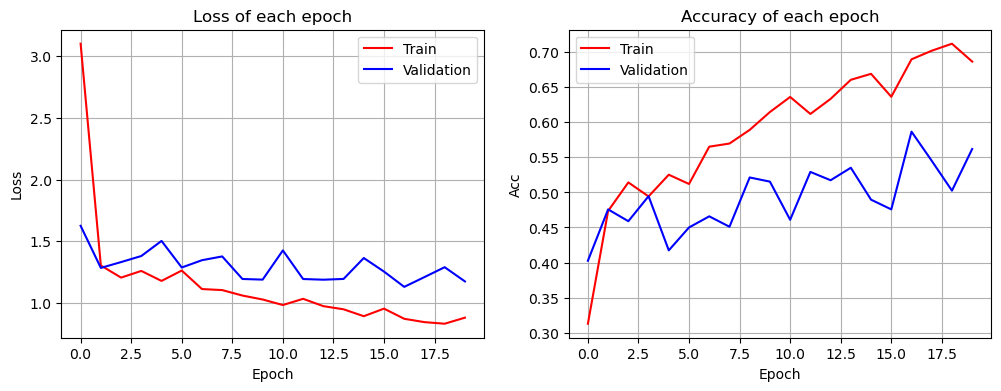

In [24]:
plt.figure(figsize=(12,4))

plt.subplot(1, 2, 1)
plt.plot(range(epoch_counter), loss_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), loss_valid_hist, 'b-', label='Validation')
plt.title('Loss of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(epoch_counter), acc_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), acc_valid_hist, 'b-', label='Validation')
plt.title('Accuracy of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Acc')
plt.grid(True)
plt.legend()

## ReLU Model

### Initial Loss

In [25]:
set_seed(seed)
model2 = ReLUModel().to(device)
loss_fn = nn.CrossEntropyLoss()

inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)
targets = targets.to(device)

with torch.no_grad():
  outputs = model2(inputs)
  loss = loss_fn(outputs, targets)

print(loss)

tensor(1.6267, device='cuda:0')


### Best Learning Rate

In [26]:
set_seed(seed)
loss_fn = nn.CrossEntropyLoss()

num_epochs = 3

for lr in [0.3, 0.1, 0.01, 0.001, 0.0001]:
  print(f'LR={lr}')

  model2 = ReLUModel().to(device)
  optimizer = torch.optim.Adam(model2.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model2, _, _ = train_one_epoch(model2, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.3


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.42batch/s, accuracy=19.8, loss=1.82]



LR=0.1


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.45batch/s, accuracy=19.8, loss=1.63]



LR=0.01


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.49batch/s, accuracy=19.8, loss=1.61]



LR=0.001


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.46batch/s, accuracy=19.8, loss=4.12]



LR=0.0001


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.49batch/s, accuracy=19.8, loss=2.88]

### Train

In [43]:
loss_train_hist_relu = []
loss_valid_hist_relu = []

acc_train_hist_relu = []
acc_valid_hist_relu = []

best_loss_valid_relu = torch.inf
epoch_counter_relu = 0

In [46]:
set_seed(seed)
model2 = ReLUModel().to(device)

optimizer = optim.Adam(model2.parameters(), lr=0.0001)
loss_fn = nn.CrossEntropyLoss()

In [ ]:
num_epochs = 10

for epoch in range(num_epochs):
  model2, loss_train, acc_train = train_one_epoch(model2, train_loader, loss_fn, optimizer, epoch_counter_relu + 1)

  loss_valid, acc_valid = validation(model2, valid_loader, loss_fn)
  
  loss_train_hist_relu.append(loss_train)
  loss_valid_hist_relu.append(loss_valid)

  acc_train_hist_relu.append(acc_train)
  acc_valid_hist_relu.append(acc_valid)
  
  if loss_valid < best_loss_valid_relu:
    torch.save(model2, f'./models/ReLU Model.pt')
    best_loss_valid_relu = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
  print()

  epoch_counter_relu += 1

Epoch 1: 100%|██████████| 32/32 [00:23<00:00,  1.37batch/s, accuracy=34.6, loss=2.05]


Model Saved.
Valid: Loss = 1.419, Acc = 0.3887



Epoch 2: 100%|██████████| 32/32 [00:23<00:00,  1.35batch/s, accuracy=44, loss=1.35]  


Model Saved.
Valid: Loss = 1.309, Acc = 0.4461



Epoch 3: 100%|██████████| 32/32 [00:22<00:00,  1.40batch/s, accuracy=47.2, loss=1.27]


Model Saved.
Valid: Loss = 1.283, Acc = 0.4827



... (10 outputs left out)

Epoch 9: 100%|██████████| 32/32 [00:23<00:00,  1.38batch/s, accuracy=59.5, loss=1.06]


Model Saved.
Valid: Loss = 1.157, Acc = 0.5519



Epoch 10: 100%|██████████| 32/32 [00:23<00:00,  1.38batch/s, accuracy=58.8, loss=1.06]


Model Saved.
Valid: Loss = 1.143, Acc = 0.5569



In [ ]:
num_epochs = 10

for epoch in range(num_epochs):
  model2, loss_train, acc_train = train_one_epoch(model2, train_loader, loss_fn, optimizer, epoch_counter_relu + 1)

  loss_valid, acc_valid = validation(model2, valid_loader, loss_fn)
  
  loss_train_hist_relu.append(loss_train)
  loss_valid_hist_relu.append(loss_valid)

  acc_train_hist_relu.append(acc_train)
  acc_valid_hist_relu.append(acc_valid)
  
  if loss_valid < best_loss_valid_relu:
    torch.save(model2, f'./models/ReLU Model.pt')
    best_loss_valid_relu = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
  print()

  epoch_counter_relu += 1

Epoch 11: 100%|██████████| 32/32 [00:23<00:00,  1.36batch/s, accuracy=61.5, loss=1.02]


Valid: Loss = 1.326, Acc = 0.4955



Epoch 12: 100%|██████████| 32/32 [00:23<00:00,  1.36batch/s, accuracy=61.1, loss=1.03]


Valid: Loss = 1.162, Acc = 0.5242



Epoch 13: 100%|██████████| 32/32 [00:23<00:00,  1.35batch/s, accuracy=62.7, loss=0.993]


Valid: Loss = 1.227, Acc = 0.5203



... (10 outputs left out)

Epoch 19: 100%|██████████| 32/32 [00:23<00:00,  1.34batch/s, accuracy=65.5, loss=0.925]


Model Saved.
Valid: Loss = 1.114, Acc = 0.5579



Epoch 20: 100%|██████████| 32/32 [00:23<00:00,  1.34batch/s, accuracy=67.2, loss=0.899]


Valid: Loss = 1.262, Acc = 0.5074



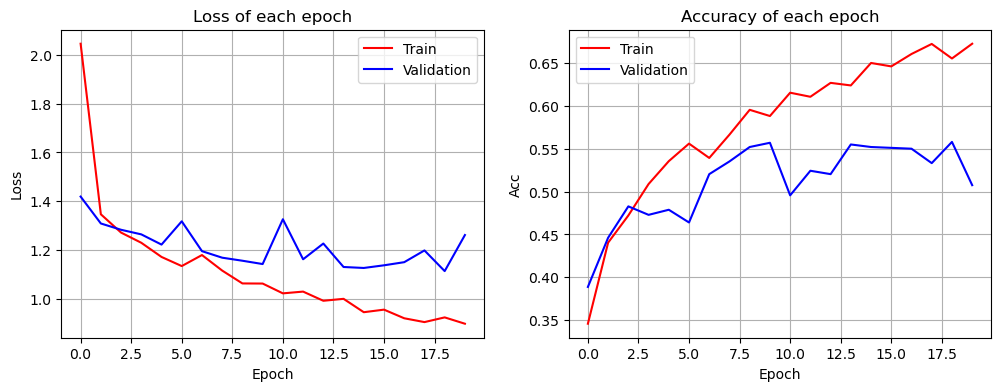

In [31]:
plt.figure(figsize=(12,4))

plt.subplot(1, 2, 1)
plt.plot(range(epoch_counter_relu), loss_train_hist_relu, 'r-', label='Train')
plt.plot(range(epoch_counter_relu), loss_valid_hist_relu, 'b-', label='Validation')
plt.title('Loss of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(epoch_counter_relu), acc_train_hist_relu, 'r-', label='Train')
plt.plot(range(epoch_counter_relu), acc_valid_hist_relu, 'b-', label='Validation')
plt.title('Accuracy of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Acc')
plt.grid(True)
plt.legend()

## Improved NN

### Initial Loss

In [10]:
set_seed(seed)
model3 = ImprovedNN().to(device)
loss_fn = nn.CrossEntropyLoss()

inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)
targets = targets.to(device)

with torch.no_grad():
  outputs = model3(inputs)
  loss = loss_fn(outputs, targets)

print(loss)

tensor(1.7014, device='cuda:0')


### Best Learning Rate

In [11]:
set_seed(seed)
loss_fn = nn.CrossEntropyLoss()

num_epochs = 3

for lr in [0.3, 0.1, 0.01, 0.001, 0.0001]:
  print(f'LR={lr}')

  model3 = ImprovedNN().to(device)
  optimizer = torch.optim.Adam(model3.parameters(), lr=lr, weight_decay=1e-4)

  for epoch in range(num_epochs):
    model3, _, _ = train_one_epoch(model3, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.3


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.39batch/s, accuracy=3.17, loss=1.91] 



LR=0.1


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.47batch/s, accuracy=2.87, loss=1.63]



LR=0.01


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.54batch/s, accuracy=17.4, loss=1.75] 



LR=0.001


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.46batch/s, accuracy=23, loss=1.69]  



LR=0.0001


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.57batch/s, accuracy=22.1, loss=1.68]

### Train with Early Stopping

In [12]:
loss_train_hist_improved = []
loss_valid_hist_improved = []

acc_train_hist_improved = []
acc_valid_hist_improved = []

best_loss_valid_improved = torch.inf
epoch_counter_improved = 0

In [13]:
set_seed(seed)
model3 = ImprovedNN().to(device)

optimizer = optim.Adam(model3.parameters(), lr=0.0001, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()

In [ ]:
num_epochs = 20
patience = 5
counter = 0

for epoch in range(num_epochs):
    model3, loss_train, acc_train = train_one_epoch(model3, train_loader, loss_fn, optimizer, epoch_counter_improved + 1)

    loss_valid, acc_valid = validation(model3, valid_loader, loss_fn)

    loss_train_hist_improved.append(loss_train)
    loss_valid_hist_improved.append(loss_valid)

    acc_train_hist_improved.append(acc_train)
    acc_valid_hist_improved.append(acc_valid)

    if loss_valid < best_loss_valid_improved:
        best_loss_valid_improved = loss_valid
        counter = 0
        torch.save(model3, './models/Improved Model.pt')
        print('Model saved.')
    else:
        counter += 1
        print(f'No improvement for {counter} epochs')

    print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
    print()

    if counter >= patience:
        print('Early stopping!')
        break

    epoch_counter_improved += 1


Epoch 1: 100%|██████████| 32/32 [00:27<00:00,  1.16batch/s, accuracy=38.7, loss=1.44]


Model saved.
Valid: Loss = 1.338, Acc = 0.4431



Epoch 2: 100%|██████████| 32/32 [00:22<00:00,  1.40batch/s, accuracy=46.9, loss=1.31]


Model saved.
Valid: Loss = 1.264, Acc = 0.4936



Epoch 3: 100%|██████████| 32/32 [00:22<00:00,  1.41batch/s, accuracy=50.8, loss=1.23]


Model saved.
Valid: Loss = 1.239, Acc = 0.4936



... (30 outputs left out)

Epoch 19: 100%|██████████| 32/32 [00:23<00:00,  1.36batch/s, accuracy=84.8, loss=0.595]


No improvement for 1 epochs
Valid: Loss = 1.101, Acc = 0.5836



Epoch 20: 100%|██████████| 32/32 [00:23<00:00,  1.38batch/s, accuracy=84.4, loss=0.578]


No improvement for 2 epochs
Valid: Loss = 1.156, Acc = 0.5223



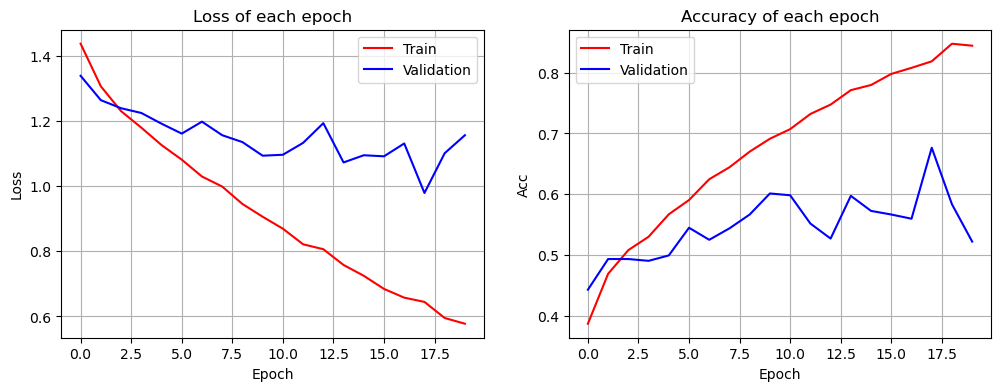

In [15]:
plt.figure(figsize=(12,4))

plt.subplot(1, 2, 1)
plt.plot(range(epoch_counter_improved), loss_train_hist_improved, 'r-', label='Train')
plt.plot(range(epoch_counter_improved), loss_valid_hist_improved, 'b-', label='Validation')
plt.title('Loss of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(epoch_counter_improved), acc_train_hist_improved, 'r-', label='Train')
plt.plot(range(epoch_counter_improved), acc_valid_hist_improved, 'b-', label='Validation')
plt.title('Accuracy of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Acc')
plt.grid(True)
plt.legend()

## AlexNet

### Initial Loss

In [41]:
set_seed(seed)
model4 = AlexNet5().to(device)
loss_fn = nn.CrossEntropyLoss()

inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)
targets = targets.to(device)

with torch.no_grad():
  outputs = model4(inputs)
  loss = loss_fn(outputs, targets)

print(loss)

tensor(1.6960, device='cuda:0')


### Best Learning Rate

In [43]:
set_seed(seed)
loss_fn = nn.CrossEntropyLoss()

num_epochs = 3

for lr in [0.3, 0.1, 0.01, 0.001, 0.0001]:
  print(f'LR={lr}')

  model4 = AlexNet5().to(device)
  optimizer = torch.optim.Adam(model4.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model4, _, _ = train_one_epoch(model4, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.3


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.45batch/s, accuracy=19.9, loss=1.74]



LR=0.1


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.42batch/s, accuracy=23.7, loss=157] 



LR=0.01


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.43batch/s, accuracy=21.3, loss=93.3]



LR=0.001


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.43batch/s, accuracy=12.1, loss=1.77]



LR=0.0001


Epoch 3: 100%|██████████| 8/8 [00:05<00:00,  1.47batch/s, accuracy=66.1, loss=1.1] 

### Train

In [19]:
set_seed(seed)
model4 = AlexNet5().to(device)

optimizer = optim.Adam(model4.parameters(), lr=0.0001)
loss_fn = nn.CrossEntropyLoss()

In [20]:
loss_train_hist_alexnet = []
loss_valid_hist_alexnet = []

acc_train_hist_alexnet = []
acc_valid_hist_alexnet = []

best_loss_valid_alexnet = torch.inf
epoch_counter_alexnet = 0

In [ ]:
num_epochs = 10

for epoch in range(num_epochs):
  model4, loss_train, acc_train = train_one_epoch(model4, train_loader, loss_fn, optimizer, epoch_counter_alexnet + 1)

  loss_valid, acc_valid = validation(model4, valid_loader, loss_fn)
  
  loss_train_hist_alexnet.append(loss_train)
  loss_valid_hist_alexnet.append(loss_valid)

  acc_train_hist_alexnet.append(acc_train)
  acc_valid_hist_alexnet.append(acc_valid)
  
  if loss_valid < best_loss_valid_alexnet:
    torch.save(model4, f'./models/AlexNet Model.pt')
    best_loss_valid_alexnet = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
  print()

  epoch_counter_alexnet += 1

Epoch 1: 100%|██████████| 32/32 [00:22<00:00,  1.40batch/s, accuracy=43.8, loss=1.35]


Model Saved.
Valid: Loss = 1.078, Acc = 0.6518



Epoch 2: 100%|██████████| 32/32 [00:22<00:00,  1.44batch/s, accuracy=66.6, loss=0.97] 


Model Saved.
Valid: Loss = 0.8626, Acc = 0.731



Epoch 3: 100%|██████████| 32/32 [00:22<00:00,  1.44batch/s, accuracy=71.6, loss=0.833]


Model Saved.
Valid: Loss = 0.7562, Acc = 0.7636



... (10 outputs left out)

Epoch 9: 100%|██████████| 32/32 [00:22<00:00,  1.45batch/s, accuracy=80.6, loss=0.57] 


Model Saved.
Valid: Loss = 0.5411, Acc = 0.8358



Epoch 10: 100%|██████████| 32/32 [00:22<00:00,  1.44batch/s, accuracy=81.1, loss=0.553]


Model Saved.
Valid: Loss = 0.5298, Acc = 0.8388



In [ ]:
num_epochs = 10

for epoch in range(num_epochs):
  model4, loss_train, acc_train = train_one_epoch(model4, train_loader, loss_fn, optimizer, epoch_counter_alexnet + 1)

  loss_valid, acc_valid = validation(model4, valid_loader, loss_fn)
  
  loss_train_hist_alexnet.append(loss_train)
  loss_valid_hist_alexnet.append(loss_valid)

  acc_train_hist_alexnet.append(acc_train)
  acc_valid_hist_alexnet.append(acc_valid)
  
  if loss_valid < best_loss_valid_alexnet:
    torch.save(model4, f'./models/AlexNet Model.pt')
    best_loss_valid_alexnet = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
  print()

  epoch_counter_alexnet += 1

Epoch 11: 100%|██████████| 32/32 [00:24<00:00,  1.29batch/s, accuracy=81.7, loss=0.541]


Model Saved.
Valid: Loss = 0.514, Acc = 0.8427



Epoch 12: 100%|██████████| 32/32 [00:22<00:00,  1.44batch/s, accuracy=82.7, loss=0.522]


Model Saved.
Valid: Loss = 0.5032, Acc = 0.8457



Epoch 13: 100%|██████████| 32/32 [00:23<00:00,  1.37batch/s, accuracy=82.8, loss=0.512]


Model Saved.
Valid: Loss = 0.493, Acc = 0.8457



... (10 outputs left out)

Epoch 19: 100%|██████████| 32/32 [00:23<00:00,  1.35batch/s, accuracy=84.8, loss=0.45] 


Model Saved.
Valid: Loss = 0.4475, Acc = 0.8605



Epoch 20: 100%|██████████| 32/32 [00:22<00:00,  1.42batch/s, accuracy=84.3, loss=0.453]


Model Saved.
Valid: Loss = 0.441, Acc = 0.8645



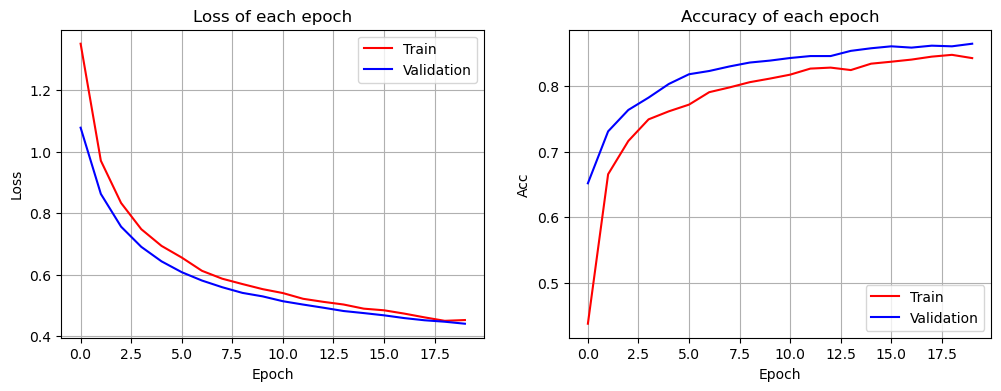

In [24]:
plt.figure(figsize=(12,4))

plt.subplot(1, 2, 1)
plt.plot(range(epoch_counter_alexnet), loss_train_hist_alexnet, 'r-', label='Train')
plt.plot(range(epoch_counter_alexnet), loss_valid_hist_alexnet, 'b-', label='Validation')
plt.title('Loss of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(epoch_counter_alexnet), acc_train_hist_alexnet, 'r-', label='Train')
plt.plot(range(epoch_counter_alexnet), acc_valid_hist_alexnet, 'b-', label='Validation')
plt.title('Accuracy of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Acc')
plt.grid(True)
plt.legend()

## VGG16

### Initial Loss

In [10]:
set_seed(seed)
model5 = VGG16_5().to(device)
loss_fn = nn.CrossEntropyLoss()

inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)
targets = targets.to(device)

with torch.no_grad():
  outputs = model5(inputs)
  loss = loss_fn(outputs, targets)

print(loss)

tensor(1.6612, device='cuda:0')


### Best Learning Rate

In [11]:
set_seed(seed)
loss_fn = nn.CrossEntropyLoss()

num_epochs = 3

for lr in [0.3, 0.1, 0.01, 0.001, 0.0001]:
  print(f'LR={lr}')

  model5 = VGG16_5().to(device)
  optimizer = torch.optim.Adam(model5.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model5, _, _ = train_one_epoch(model5, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.3


Epoch 3: 100%|██████████| 8/8 [00:08<00:00,  1.06s/batch, accuracy=17, loss=175]  



LR=0.1


Epoch 3: 100%|██████████| 8/8 [00:09<00:00,  1.13s/batch, accuracy=22, loss=71]    



LR=0.01


Epoch 3: 100%|██████████| 8/8 [00:08<00:00,  1.07s/batch, accuracy=19.3, loss=5.84]



LR=0.001


Epoch 3: 100%|██████████| 8/8 [00:08<00:00,  1.07s/batch, accuracy=36.8, loss=1.53]



LR=0.0001


Epoch 3: 100%|██████████| 8/8 [00:08<00:00,  1.07s/batch, accuracy=22, loss=1.64]  

### Train

In [25]:
set_seed(seed)
model5 = VGG16_5().to(device)

optimizer = optim.Adam(model5.parameters(), lr=0.0001)
loss_fn = nn.CrossEntropyLoss()

In [26]:
loss_train_hist_vgg = []
loss_valid_hist_vgg = []

acc_train_hist_vgg = []
acc_valid_hist_vgg = []

best_loss_valid_vgg = torch.inf
epoch_counter_vgg = 0

In [ ]:
num_epochs = 20

for epoch in range(num_epochs):
  model5, loss_train, acc_train = train_one_epoch(model5, train_loader, loss_fn, optimizer, epoch_counter_vgg + 1)

  loss_valid, acc_valid = validation(model5, valid_loader, loss_fn)
  
  loss_train_hist_vgg.append(loss_train)
  loss_valid_hist_vgg.append(loss_valid)

  acc_train_hist_vgg.append(acc_train)
  acc_valid_hist_vgg.append(acc_valid)
  
  if loss_valid < best_loss_valid_vgg:
    torch.save(model5, f'./models/VGG Model.pt')
    best_loss_valid_vgg = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
  print()

  epoch_counter_vgg += 1

Epoch 1: 100%|██████████| 32/32 [00:36<00:00,  1.15s/batch, accuracy=37.2, loss=1.47]


Model Saved.
Valid: Loss = 1.285, Acc = 0.6182



Epoch 2: 100%|██████████| 32/32 [00:36<00:00,  1.15s/batch, accuracy=57.9, loss=1.19]


Model Saved.
Valid: Loss = 1.098, Acc = 0.6775



Epoch 3: 100%|██████████| 32/32 [00:36<00:00,  1.14s/batch, accuracy=65.3, loss=1.04]


Model Saved.
Valid: Loss = 0.9862, Acc = 0.7102



... (30 outputs left out)

Epoch 19: 100%|██████████| 32/32 [00:41<00:00,  1.30s/batch, accuracy=79, loss=0.61]   


Model Saved.
Valid: Loss = 0.6298, Acc = 0.7933



Epoch 20: 100%|██████████| 32/32 [00:39<00:00,  1.25s/batch, accuracy=79.2, loss=0.598]


Model Saved.
Valid: Loss = 0.6221, Acc = 0.7953



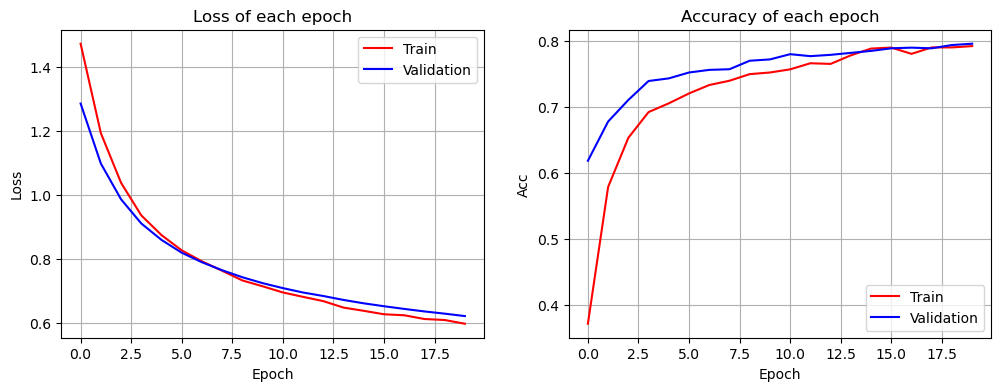

In [28]:
plt.figure(figsize=(12,4))

plt.subplot(1, 2, 1)
plt.plot(range(epoch_counter_vgg), loss_train_hist_vgg, 'r-', label='Train')
plt.plot(range(epoch_counter_vgg), loss_valid_hist_vgg, 'b-', label='Validation')
plt.title('Loss of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(epoch_counter_vgg), acc_train_hist_vgg, 'r-', label='Train')
plt.plot(range(epoch_counter_vgg), acc_valid_hist_vgg, 'b-', label='Validation')
plt.title('Accuracy of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Acc')
plt.grid(True)
plt.legend()